In [32]:
import matplotlib.pyplot as plt
import numpy as np
import keras_ocr
from PIL import Image
import random
import pickle

In [2]:
from tensorflow.keras.layers import StringLookup
from tensorflow import keras

import tensorflow as tf
import os

np.random.seed(42)
tf.random.set_seed(42)

In [47]:
# Retrive data

with open('test_data.bin', 'rb') as f:
    data = pickle.load(f)


# data = [boxes, centers, prediction_groups, images]

boxes = data[0]
centers = data[1]
prediction_groups = data[2]
images = data[3]


In [3]:
from keras.backend import manual_variable_initialization 
manual_variable_initialization(True)

---

The image needs to be a jpeg file. This is more suitable for the application.

In [4]:
tf_img = tf.io.read_file("image_50402305.JPG")
tf_img = tf.image.decode_jpeg(tf_img, 1)

In [5]:
tf_img.shape

TensorShape([3548, 2447, 1])

In [6]:
pipeline = keras_ocr.pipeline.Pipeline()

images = [keras_ocr.tools.read("image_50402305_bw.JPG"), keras_ocr.tools.read("image_50402305.JPG")]

prediction_groups = pipeline.recognize(images) # Note that an image from the directory can be passed here

Looking for C:\Users\sures\.keras-ocr\craft_mlt_25k.h5
Looking for C:\Users\sures\.keras-ocr\crnn_kurapan.h5
13/13 [==============================] - 43s 3s/step


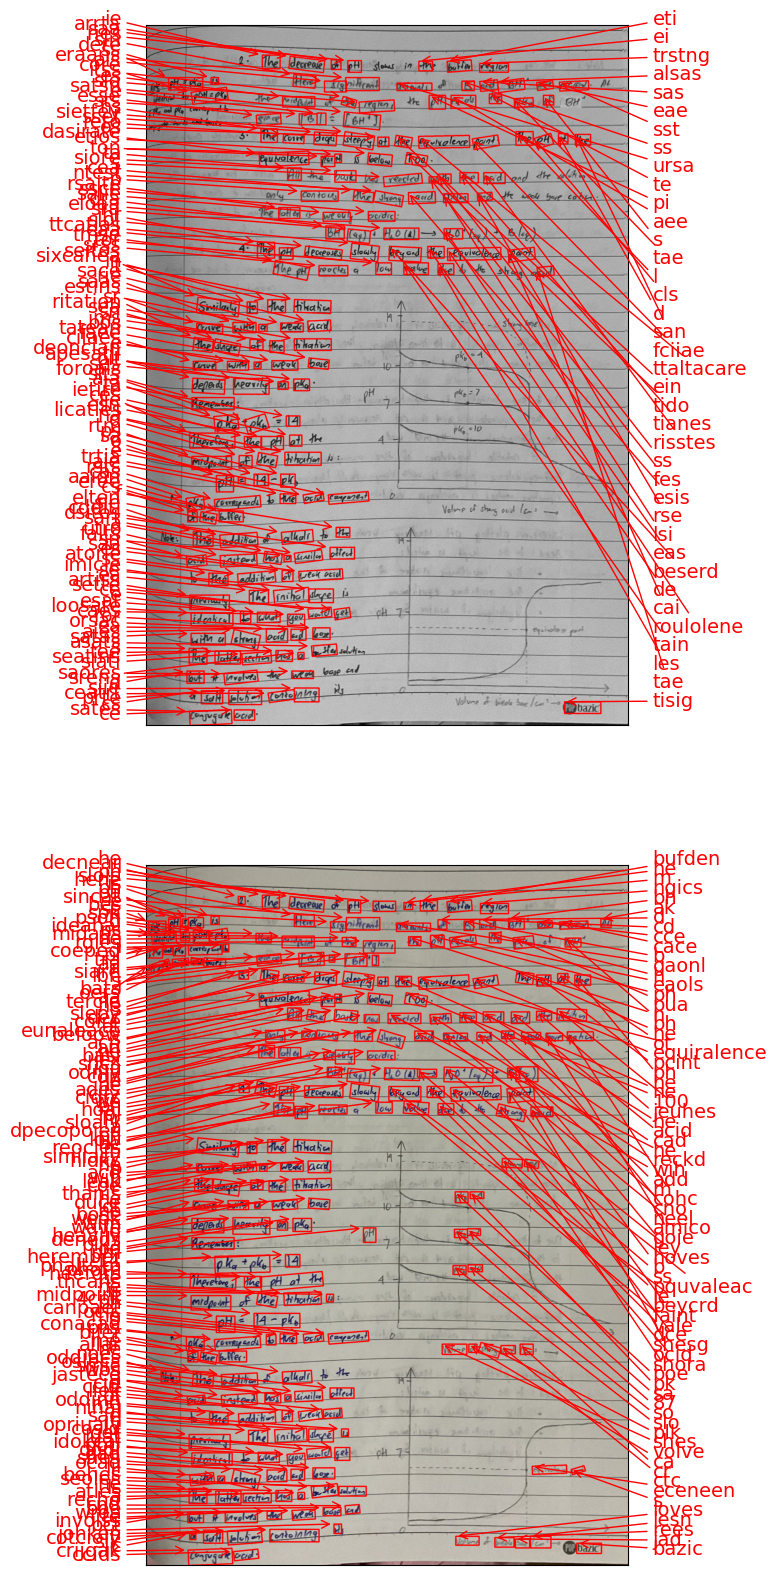

In [7]:
fig, axs = plt.subplots(nrows=len(images), figsize=(10, 20))
for ax, image, predictions in zip(axs, images, prediction_groups):
    keras_ocr.tools.drawAnnotations(image=image, 
                                    predictions=predictions, 
                                    ax=ax)

# Easyocr

In [8]:
import easyocr

reader = easyocr.Reader(['en'], gpu=False)

C:\Users\sures\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Using CPU. Note: This module is much faster with a GPU.


In [9]:
image = keras_ocr.tools.read("image_50402305.JPG")
results = reader.readtext(image)

In [10]:
PlotRes = [ (word[1], np.array(word[0])) for word in results]

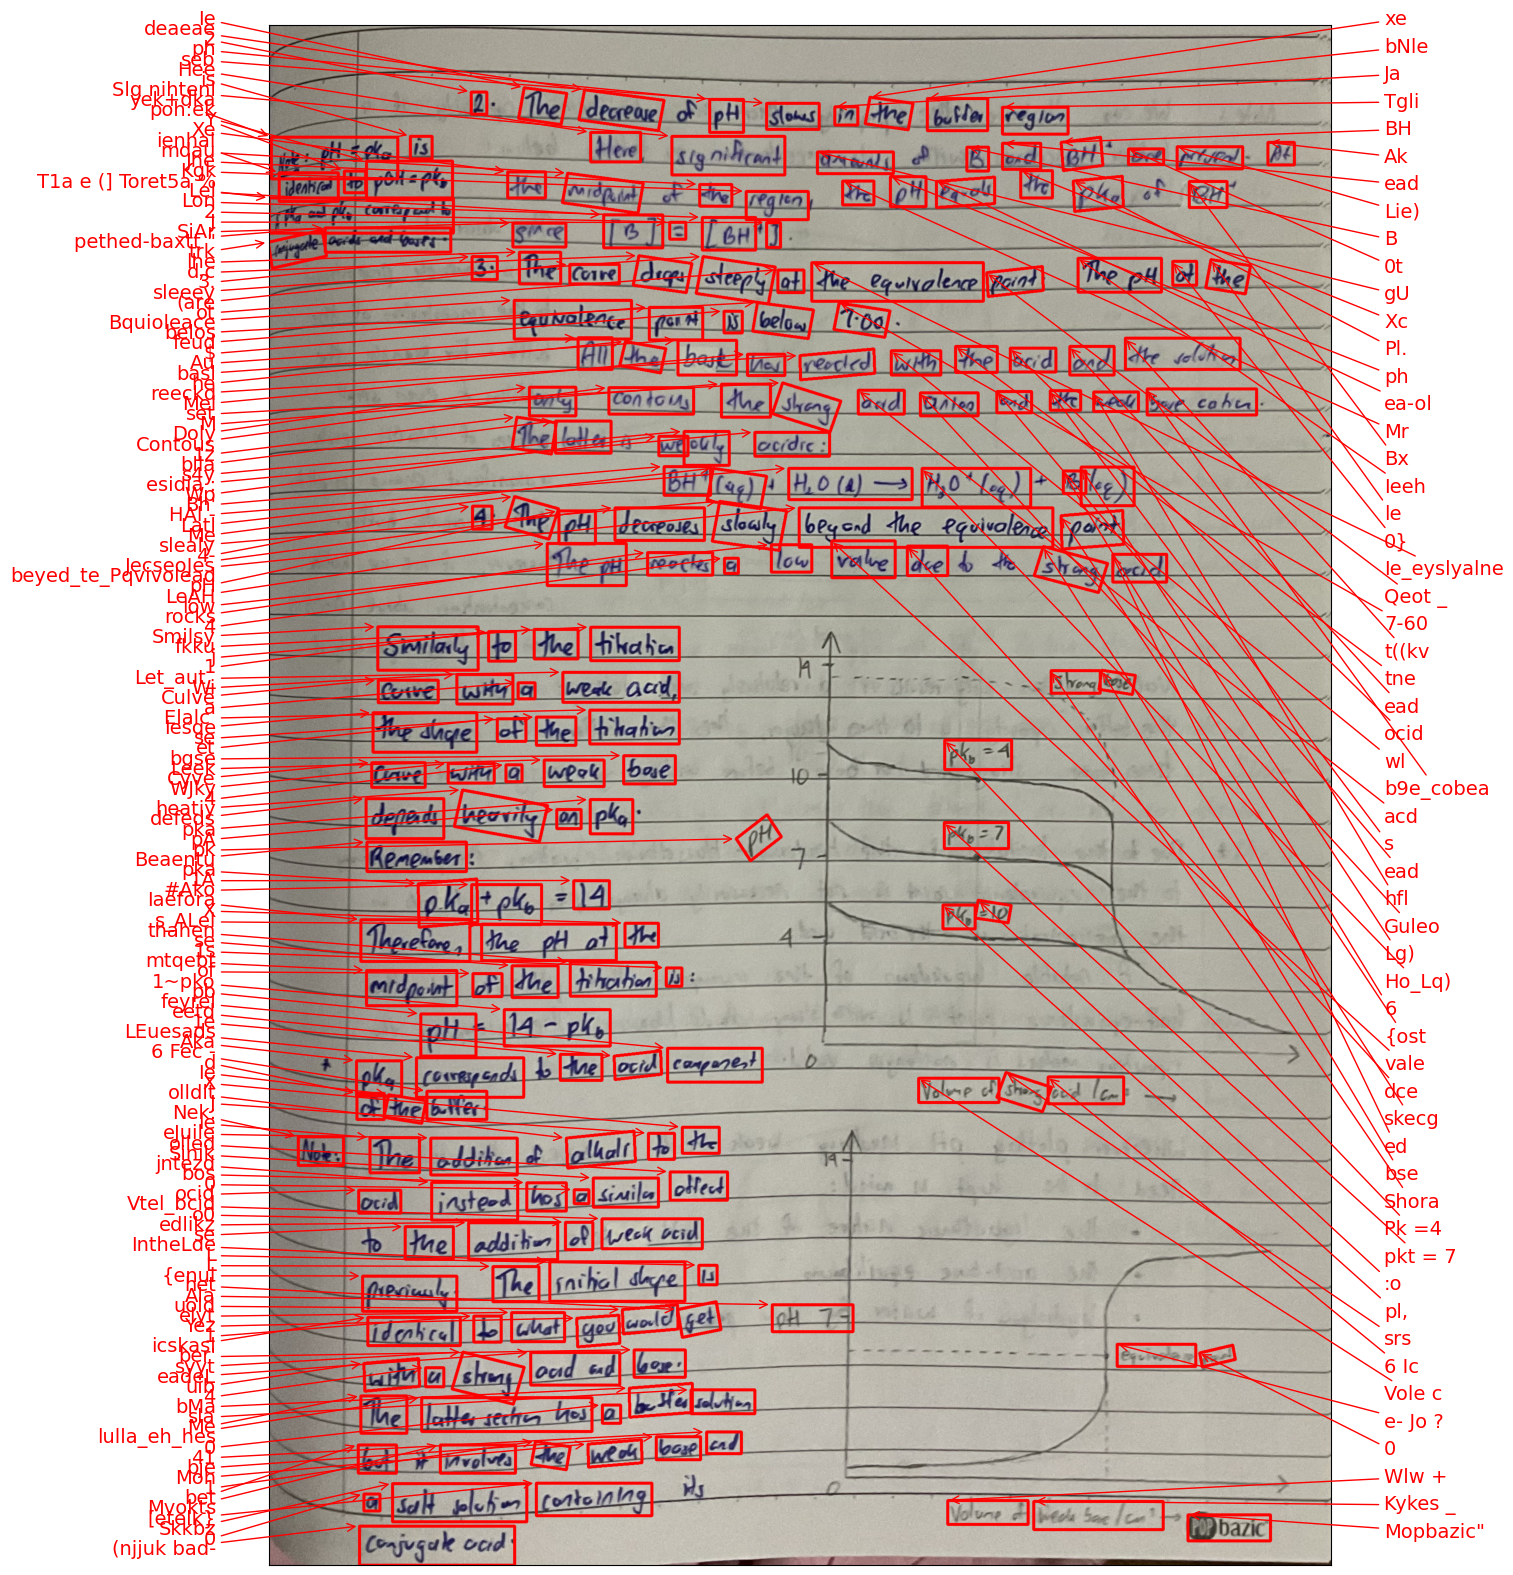

In [11]:
fig, axs = plt.subplots(nrows=1, figsize=(20, 20))
keras_ocr.tools.drawAnnotations(image=image, predictions=PlotRes, ax=axs)
plt.show()

In [12]:
prediction_groups.append(PlotRes)
images.append(image)

# Character recognition (Keras)

Pre-processing to be done for the image:
- resizing images
- convert to tensorflow formatting
- label vectorization

In [13]:
# These parameters may need to be updated based on the training of the model

batch_size = 64
padding_token = 99
image_width = 128
image_height = 32
max_len = 21

In [14]:
AUTOTUNE = tf.data.AUTOTUNE

characters = ['!',
 '"',
 '#',
 '&',
 "'",
 '(',
 ')',
 '*',
 '+',
 ',',
 '-',
 '.',
 '/',
 '0',
 '1',
 '2',
 '3',
 '4',
 '5',
 '6',
 '7',
 '8',
 '9',
 ':',
 ';',
 '?',
 'A',
 'B',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'J',
 'K',
 'L',
 'M',
 'N',
 'O',
 'P',
 'Q',
 'R',
 'S',
 'T',
 'U',
 'V',
 'W',
 'X',
 'Y',
 'Z',
 'a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

# Mapping characters to integers.
char_to_num = StringLookup(vocabulary=list(characters), mask_token=None)

# Mapping integers back to original characters.
num_to_char = StringLookup(
    vocabulary=char_to_num.get_vocabulary(), mask_token=None, invert=True
)

In [15]:
def distortion_free_resize(image, img_size):
    w, h = img_size
    image = tf.image.resize(image, size=(h, w), preserve_aspect_ratio=True)

    # Check tha amount of padding needed to be done.
    pad_height = h - tf.shape(image)[0]
    pad_width = w - tf.shape(image)[1]

    # Only necessary if you want to do same amount of padding on both sides.
    if pad_height % 2 != 0:
        height = pad_height // 2
        pad_height_top = height + 1
        pad_height_bottom = height
    else:
        pad_height_top = pad_height_bottom = pad_height // 2

    if pad_width % 2 != 0:
        width = pad_width // 2
        pad_width_left = width + 1
        pad_width_right = width
    else:
        pad_width_left = pad_width_right = pad_width // 2

    image = tf.pad(
        image,
        paddings=[
            [pad_height_top, pad_height_bottom],
            [pad_width_left, pad_width_right],
            [0, 0],
        ],
    )

    image = tf.transpose(image, perm=[1, 0, 2])
    image = tf.image.flip_left_right(image)
    return image

def preprocess_image(image, img_size=(image_width, image_height)):
    image = distortion_free_resize(image, img_size)
    image = tf.cast(image, tf.float32) / 255.0
    return image

In [16]:
class CTCLayer(keras.layers.Layer):
    def __init__(self, name=None):
        super().__init__(name=name)
        self.loss_fn = keras.backend.ctc_batch_cost

    def call(self, y_true, y_pred):
        batch_len = tf.cast(tf.shape(y_true)[0], dtype="int64")
        input_length = tf.cast(tf.shape(y_pred)[1], dtype="int64")
        label_length = tf.cast(tf.shape(y_true)[1], dtype="int64")

        input_length = input_length * tf.ones(shape=(batch_len, 1), dtype="int64")
        label_length = label_length * tf.ones(shape=(batch_len, 1), dtype="int64")
        loss = self.loss_fn(y_true, y_pred, input_length, label_length)
        self.add_loss(loss)

        # At test time, just return the computed predictions.
        return y_pred


def build_model():
    # Inputs to the model
    input_img = keras.Input(shape=(image_width, image_height, 1), name="image")
    labels = keras.layers.Input(name="label", shape=(None,))

    # First conv block.
    x = keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        kernel_initializer="he_normal",
        padding="same",
        name="Conv1",
    )(input_img)
    x = keras.layers.MaxPooling2D((2, 2), name="pool1")(x)

    # Second conv block.
    x = keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        kernel_initializer="he_normal",
        padding="same",
        name="Conv2",
    )(x)
    x = keras.layers.MaxPooling2D((2, 2), name="pool2")(x)

    # We have used two max pool with pool size and strides 2.
    # Hence, downsampled feature maps are 4x smaller. The number of
    # filters in the last layer is 64. Reshape accordingly before
    # passing the output to the RNN part of the model.
    new_shape = ((image_width // 4), (image_height // 4) * 64)
    x = keras.layers.Reshape(target_shape=new_shape, name="reshape")(x)
    x = keras.layers.Dense(64, activation="relu", name="dense1")(x)
    x = keras.layers.Dropout(0.2)(x)

    # RNNs.
    x = keras.layers.Bidirectional(
        keras.layers.LSTM(128, return_sequences=True, dropout=0.25)
    )(x)
    x = keras.layers.Bidirectional(
        keras.layers.LSTM(64, return_sequences=True, dropout=0.25)
    )(x)

    # +2 is to account for the two special tokens introduced by the CTC loss.
    # The recommendation comes here: https://git.io/J0eXP.
    x = keras.layers.Dense(
        len(char_to_num.get_vocabulary()) + 2, activation="softmax", name="dense2"
    )(x)

    # Add CTC layer for calculating CTC loss at each step.
    output = CTCLayer(name="ctc_loss")(labels, x)

    # Define the model.
    model = keras.models.Model(
        inputs=[input_img, labels], outputs=output, name="handwriting_recognizer"
    )
    # Optimizer.
    opt = tf.keras.optimizers.legacy.Adam()
    # Compile the model and return.
    model.compile(optimizer=opt)
    return model


# Get the model.
model = build_model()
model.summary()

Model: "handwriting_recognizer"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 image (InputLayer)             [(None, 128, 32, 1)  0           []                               
                                ]                                                                 
                                                                                                  
 Conv1 (Conv2D)                 (None, 128, 32, 32)  320         ['image[0][0]']                  
                                                                                                  
 pool1 (MaxPooling2D)           (None, 64, 16, 32)   0           ['Conv1[0][0]']                  
                                                                                                  
 Conv2 (Conv2D)                 (None, 64, 16, 64)   18496       ['pool1[0][0

In [17]:
checkpoint = tf.train.Checkpoint(model)
checkpoint.restore(os.getcwd() + "/Checkpoints/" + "HandwritingRecog").expect_partial()

In [18]:
prediction_model = keras.models.Model(
    model.get_layer(name="image").input, model.get_layer(name="dense2").output
)

In [19]:
# A utility function to decode the output of the network.
def decode_batch_predictions(pred):
    input_len = np.ones(pred.shape[0]) * pred.shape[1]
    # Use greedy search. For complex tasks, you can use beam search.
    results = keras.backend.ctc_decode(pred, input_length=input_len, greedy=True)[0][0][
        :, :max_len
    ]
    # Iterate over the results and get back the text.
    output_text = []
    for res in results:
        res = tf.gather(res, tf.where(tf.math.not_equal(res, -1)))
        res = tf.strings.reduce_join(num_to_char(res)).numpy().decode("utf-8")
        output_text.append(res)
    return output_text


# Combination

In [20]:
prediction_groups[1][1]

('l',
 array([[467.7539 , 159.38281],
        [502.40234, 159.38281],
        [502.40234, 200.96094],
        [467.7539 , 200.96094]], dtype=float32))

## Process text

In [21]:
def GetBox(Pred):
    x_max = 0
    x_min = 10000
    y_max = 0
    y_min = 10000

    for i in Pred[1]:
        x_max = max(i[0], x_max)
        x_min = min(i[0], x_min)
        y_max = max(i[1], y_max)
        y_min = min(i[1], y_min)

    # Each of these 4 variables is an edge of the box
    
    return x_max, x_min, y_max, y_min

In [22]:
# Get the word boxes as tensorflow images

def WordBox(Pred):
    x_max, x_min, y_max, y_min = GetBox(Pred)

    print("The word is identified as: ", Pred[0])

    print(int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    word = tf.image.crop_to_bounding_box(tf_img, int(y_min), int(x_min), int(y_max - y_min), int(x_max - x_min))

    return preprocess_image(word) # This returns a tensorflow image object

In [23]:
# Get the boxes and centers of each word identified

boxes = [ [] for i in range(len(prediction_groups)) ]
centers = [ [] for i in range(len(prediction_groups)) ]

for i in range(len(prediction_groups)):

    for word_num in range(len(prediction_groups[i])):
        boxes[i].append(GetBox(prediction_groups[i][word_num]))
        centers[i].append( ( (boxes[i][-1][0] + boxes[i][-1][1]) / 2 , (boxes[i][-1][2] + boxes[i][-1][3]) / 2 ) )

In [46]:
# Save data

data = [boxes, centers, prediction_groups, images]

with open('test_data.bin', 'wb') as f:
    pickle.dump(data, f)

### Text sorting

In [31]:
"""
loop for multiple sorts until no exchange happens
    loop through all the boxes and their centers:
        if the next box is:
            1. same line but to the left
            2. same vertical but above
        then swap

Note: An word that is lower than another word will have a greater y coordinate
"""

def swap(grp, i, j):
    temp = prediction_groups[grp][i]
    prediction_groups[grp][i] = prediction_groups[grp][j]
    prediction_groups[grp][j] = temp

    temp = boxes[grp][i]
    boxes[grp][i] = boxes[grp][j]
    boxes[grp][j] = temp

    temp = centers[grp][i]
    centers[grp][i] = centers[grp][j]
    centers[grp][j] = temp

    print("Swapped")

for grp in range(len(prediction_groups)):
    sorts = 1

    while sorts != 0:
        sorts = 0

        for i in range(len(prediction_groups[grp]) - 1):

            # Find if the box is on the same line
            if boxes[grp][i][2] > boxes[grp][i+1][3] and boxes[grp][i][3] < boxes[grp][i+1][2]:
                if centers[grp][i][0] > centers[grp][i+1][0]:
                    swap(grp, i, i+1)
                    sorts += 1
            else:
                if centers[grp][i][1] > centers[grp][i+1][1]:
                    swap(grp, i, i+1)   
                    sorts += 1  

        print(sorts)          

Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
99
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapped
Swapp

The word is identified as:  l
159 467 41 34
0
The word is identified as:  he
152 589 69 86
1
The word is identified as:  decnear
159 723 80 180
2
The word is identified as:  ph
180 1022 62 65
3
The word is identified as:  slols
183 1150 51 114
4
The word is identified as:  m
190 1306 34 45
5
The word is identified as:  he
180 1389 51 86
6
The word is identified as:  bufden
176 1524 65 128
7
The word is identified as:  ngics
194 1694 51 142
8
The word is identified as:  bes
284 13 65 86
9


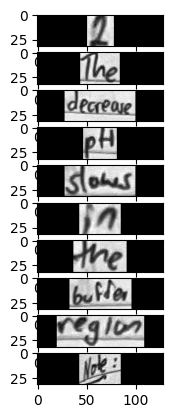

The word is identified as:  ph
266 114 69 58
10
The word is identified as:  e
273 183 38 31
11
The word is identified as:  pa
266 214 51 76
12
The word is identified as:  is
259 329 41 41
13
The word is identified as:  hene
252 751 58 100
14
The word is identified as:  ss
287 935 51 76
15
The word is identified as:  sincat
266 1015 62 169
16
The word is identified as:  gaonl
294 1268 41 173
17
The word is identified as:  d
277 1479 48 45
18
The word is identified as:  b
284 1611 48 48
19


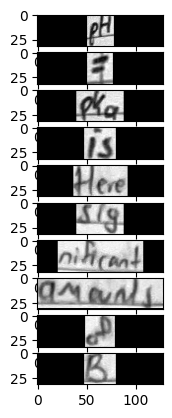

The word is identified as:  cd
277 1690 48 79
20
The word is identified as:  bh
270 1836 55 79
21
The word is identified as:  cce
282 1983 38 76
22
The word is identified as:  cace
283 2095 42 144
23
The word is identified as:  ak
273 2304 41 51
24
The word is identified as:  ideahal
343 28 57 125
25
The word is identified as:  d
343 176 41 45
26
The word is identified as:  psoh
332 239 62 83
27
The word is identified as:  spk
320 313 75 107
28
The word is identified as:  ns
346 557 48 76
29


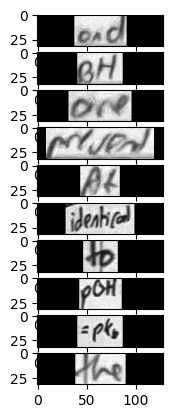

The word is identified as:  midaas
360 689 58 162
30
The word is identified as:  he
367 994 45 69
31
The word is identified as:  rgies
384 1101 62 159
32
The word is identified as:  n
363 1330 45 62
33
The word is identified as:  ph
356 1441 58 69
34
The word is identified as:  eaols
353 1537 64 136
35
The word is identified as:  h
343 1739 51 58
36
The word is identified as:  pl
408 138 51 62
37
The word is identified as:  coeped
404 214 51 171
38
The word is identified as:  l
401 391 38 27
39


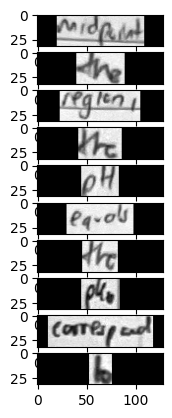

The word is identified as:  pua
358 1859 67 107
40
The word is identified as:  bh
370 2123 45 79
41
The word is identified as:  tra
415 3 55 79
42
The word is identified as:  aa
415 86 38 48
43
The word is identified as:  tercle
476 16 71 109
44
The word is identified as:  oers
472 132 41 83
45
The word is identified as:  aa
474 228 31 58
46
The word is identified as:  bats
470 292 47 110
47
The word is identified as:  siare
449 560 62 125
48
The word is identified as:  il
442 773 71 129
49


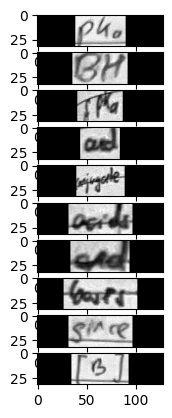

The word is identified as:  s
457 928 34 27
50
The word is identified as:  lbh
450 1008 62 110
51
The word is identified as:  j
457 1146 51 31
52
The word is identified as:  3
537 471 41 48
53
The word is identified as:  he
526 578 69 95
54
The word is identified as:  coire
554 696 38 103
55
The word is identified as:  dec
541 852 67 113
56
The word is identified as:  slepy
538 994 96 163
57
The word is identified as:  at
568 1174 45 51
58
The word is identified as:  ne
564 1264 51 79
59


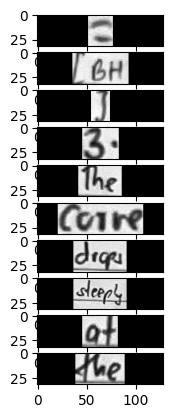

The word is identified as:  equiralence
556 1380 73 257
60
The word is identified as:  pcint
557 1656 70 130
61
The word is identified as:  he
539 1871 67 94
62
The word is identified as:  ph
557 1978 55 72
63
The word is identified as:  ot
550 2085 45 51
64
The word is identified as:  he
557 2172 51 79
65
The word is identified as:  eunaleace
638 572 81 256
66
The word is identified as:  acn
665 887 51 69
67
The word is identified as:  s
654 956 41 34
68
The word is identified as:  beloow
648 1122 67 126
69


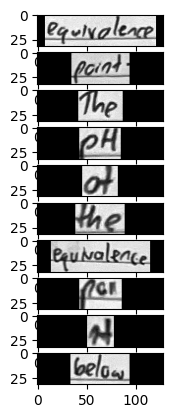

The word is identified as:  100
647 1309 71 116
70
The word is identified as:  an
724 717 62 69
71
The word is identified as:  he
732 812 66 99
72
The word is identified as:  basl
732 952 68 121
73
The word is identified as:  lex
758 1105 41 76
74
The word is identified as:  reckd
751 1226 51 166
75
The word is identified as:  wih
752 1438 53 108
76
The word is identified as:  he
748 1590 48 83
77
The word is identified as:  acid
744 1708 51 103
78
The word is identified as:  cad
744 1850 58 93
79


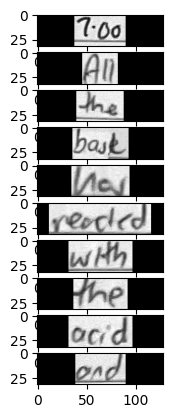

The word is identified as:  he
741 1978 45 76
80
The word is identified as:  jeuhes
728 2081 61 151
81
The word is identified as:  odnly
838 606 58 97
82
The word is identified as:  con
841 789 38 69
83
The word is identified as:  iou
836 861 56 112
84
The word is identified as:  le
841 1056 51 90
85
The word is identified as:  shcs
834 1171 96 142
86
The word is identified as:  add
841 1361 48 93
87
The word is identified as:  amico
852 1507 38 121
88
The word is identified as:  cno
848 1676 38 72
89


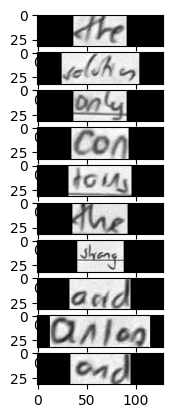

The word is identified as:  m
841 1801 38 62
90
The word is identified as:  neel
848 1902 34 97
91
The word is identified as:  goie
852 2026 38 83
92
The word is identified as:  cohc
845 2134 45 131
93
The word is identified as:  he
914 571 62 79
94
The word is identified as:  ades
925 672 51 110
95
The word is identified as:  we
949 900 38 58
96
The word is identified as:  clly
938 959 69 97
97
The word is identified as:  cidrc
942 1122 45 138
98
The word is identified as:  bh
1025 918 51 72
99


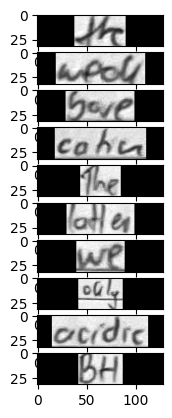

The word is identified as:  fol
1030 1017 77 119
100
The word is identified as:  hoal
1028 1207 64 179
101
The word is identified as:  ss
1035 1375 38 97
102
The word is identified as:  hoves
1024 1509 78 247
103
The word is identified as:  b
1029 1832 48 58
104
The word is identified as:  hr
1094 551 83 111
105
The word is identified as:  ley
1022 1874 76 110
106
The word is identified as:  a
1112 471 41 51
107
The word is identified as:  ph
1122 675 69 72
108
The word is identified as:  dpecopojes
1119 803 58 194
109


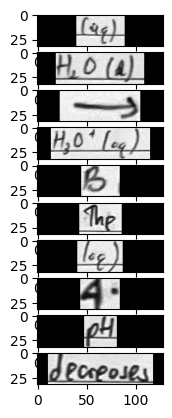

The word is identified as:  sloaly
1106 1031 93 153
110
The word is identified as:  beycrd
1122 1230 72 162
111
The word is identified as:  le
1122 1424 55 86
112
The word is identified as:  pquvaleac
1118 1543 78 256
113
The word is identified as:  low
1202 1164 55 83
114
The word is identified as:  vale
1196 1303 70 131
115
The word is identified as:  faint
1123 1828 81 141
116
The word is identified as:  he
1205 647 65 100
117
The word is identified as:  fh
1223 755 62 62
118
The word is identified as:  reocles
1216 876 45 142
119


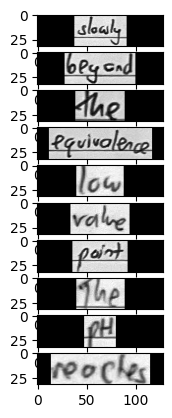

The word is identified as:  dce
1209 1479 55 79
120
The word is identified as:  shesg
1210 1773 90 153
121
The word is identified as:  ocid
1226 1950 48 110
122
The word is identified as:  similasy
1382 255 96 218
123
The word is identified as:  p
1403 512 58 48
124
The word is identified as:  he
1392 616 65 90
125
The word is identified as:  hldkc
1391 746 72 194
126
The word is identified as:  coe
1514 256 45 128
127
The word is identified as:  wih
1502 438 62 122
128
The word is identified as:  c
1517 575 34 38
129


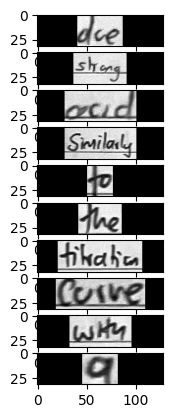

The word is identified as:  leak
1510 682 41 114
130
The word is identified as:  acd
1500 821 58 114
131
The word is identified as:  shora
1487 1803 48 103
132
The word is identified as:  boe
1490 1915 47 76
133
The word is identified as:  he
1590 246 65 90
134
The word is identified as:  duce
1590 334 87 143
135
The word is identified as:  ot
1597 530 48 62
136
The word is identified as:  he
1600 623 55 83
137
The word is identified as:  thanis
1588 743 61 195
138
The word is identified as:  bose
1688 822 58 109
139


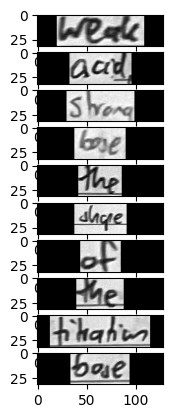

The word is identified as:  pk
1656 1566 55 65
140
The word is identified as:  sa
1656 1642 34 69
141
The word is identified as:  wave
1703 237 47 117
142
The word is identified as:  wim
1701 415 45 103
143
The word is identified as:  q
1708 550 31 27
144
The word is identified as:  weok
1696 638 54 129
145
The word is identified as:  deneds
1791 232 72 162
146
The word is identified as:  heavily
1787 440 83 187
147
The word is identified as:  oo
1808 665 41 51
148
The word is identified as:  plka
1791 744 65 93
149


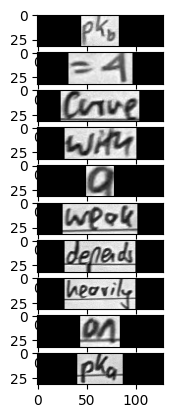

The word is identified as:  pm
1839 1101 72 62
150
The word is identified as:  so
1846 1562 41 65
151
The word is identified as:  87
1843 1628 34 65
152
The word is identified as:  herember
1888 232 58 214
153
The word is identified as:  phaltsko
1977 348 91 279
154
The word is identified as:  14
1974 706 62 72
155
The word is identified as:  photn
2060 577 99 320
156
The word is identified as:  plk
2030 1555 45 65
157
The word is identified as:  slo
2026 1631 34 72
158
The word is identified as:  heefors
2070 223 78 232
159


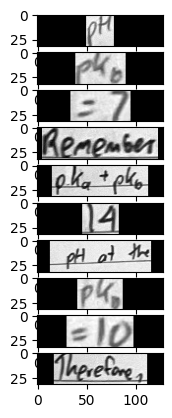

The word is identified as:  he
2085 498 55 86
160
The word is identified as:  midpoint
2182 228 72 200
161
The word is identified as:  ne
2168 559 74 108
162
The word is identified as:  thcans
2163 698 69 190
163
The word is identified as:  is
2175 914 38 34
164
The word is identified as:  ph
2286 356 83 93
165
The word is identified as:  4cpk
2272 547 72 232
166
The word is identified as:  phs
2390 204 69 90
167
The word is identified as:  conacad
2388 346 74 235
168
The word is identified as:  0
2380 609 51 48
169


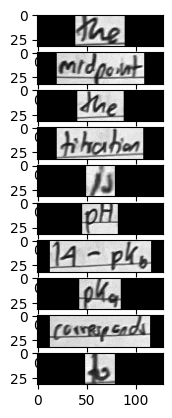

The word is identified as:  me
2376 679 48 83
170
The word is identified as:  ocic
2367 796 55 104
171
The word is identified as:  canpaet
2361 922 67 206
172
The word is identified as:  c
2466 211 51 51
173
The word is identified as:  me
2468 271 61 90
174
The word is identified as:  biler
2463 370 55 138
175
The word is identified as:  volve
2428 1500 51 124
176
The word is identified as:  ca
2428 1635 41 41
177
The word is identified as:  shes
2419 1682 80 115
178
The word is identified as:  ctc
2435 1798 41 72
179


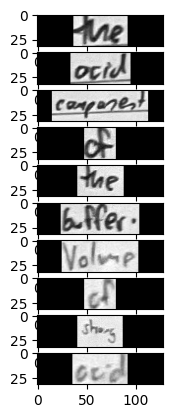

The word is identified as:  cr
2428 1895 51 65
180
The word is identified as:  noes
2567 76 55 93
181
The word is identified as:  he
2565 235 76 106
182
The word is identified as:  oddihcs
2574 381 70 185
183
The word is identified as:  allar
2561 690 70 151
184
The word is identified as:  cio
2686 208 50 92
185
The word is identified as:  jastecd
2675 381 70 183
186
The word is identified as:  wos
2674 602 51 79
187
The word is identified as:  a
2685 703 31 31
188
The word is identified as:  smic
2662 753 58 141
189


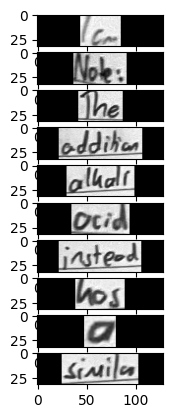

The word is identified as:  osiecs
2650 932 51 121
190
The word is identified as:  me
2775 322 62 93
191
The word is identified as:  oddinn
2771 468 65 188
192
The word is identified as:  of
2764 689 55 51
193
The word is identified as:  llek
2756 771 63 123
194
The word is identified as:  ccid
2752 897 53 96
195
The word is identified as:  opriualy
2886 218 72 207
196
The word is identified as:  h
2865 519 69 97
197
The word is identified as:  nihal
2854 651 74 164
198
The word is identified as:  sae
2858 824 65 124
199


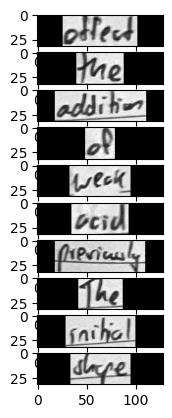

The word is identified as:  l
2858 990 38 34
200
The word is identified as:  idokcal
2979 232 62 204
201
The word is identified as:  luat
2976 568 51 107
202
The word is identified as:  goo
2981 714 63 93
203
The word is identified as:  cosld
2950 813 60 125
204
The word is identified as:  get
2952 956 65 76
205
The word is identified as:  lil
3079 221 66 125
206
The word is identified as:  shes
3063 430 102 149
207
The word is identified as:  ocad
3066 613 58 100
208
The word is identified as:  gad
3062 734 55 69
209


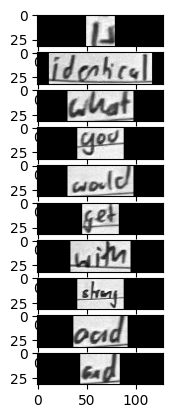

The word is identified as:  gopi
3055 845 55 110
210
The word is identified as:  eceneen
3041 1956 47 175
211
The word is identified as:  s
3044 2153 45 72
212
The word is identified as:  c
3097 363 34 34
213
The word is identified as:  he
3159 218 76 90
214
The word is identified as:  atles
3173 353 65 128
215
The word is identified as:  recho
3184 492 48 142
216
The word is identified as:  ls
3170 658 55 79
217
The word is identified as:  a
3180 769 34 34
218
The word is identified as:  behes
3135 836 72 138
219


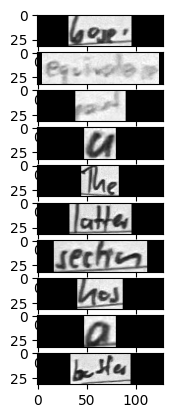

The word is identified as:  seoles
3149 977 48 138
220
The word is identified as:  bct
3281 211 51 79
221
The word is identified as:  involss
3277 401 55 162
222
The word is identified as:  te
3274 613 41 72
223
The word is identified as:  wroa
3265 739 56 119
224
The word is identified as:  boe
3256 897 41 90
225
The word is identified as:  cnd
3241 1008 48 75
226
The word is identified as:  slk
3371 291 65 97
227
The word is identified as:  johken
3362 411 83 177
228
The word is identified as:  cotcioly
3367 627 62 249
229


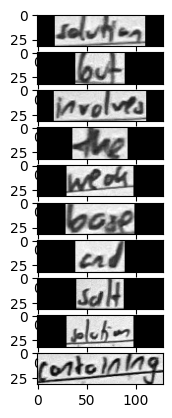

In [32]:
pred = 1

for words in range( int( len(prediction_groups[pred]) / 10 ) ):
    _, ax = plt.subplots(10, 1)

    for i in range(10):
        index = words * 10 + i
        
        image = WordBox(prediction_groups[pred][index])

        image = tf.image.flip_left_right(image)
        image = tf.transpose(image, perm=[1, 0, 2])

        ax[i].imshow(image, cmap="gray")

        print(index)

    plt.show()

# This presents the problem

In [138]:
ths = []

for i in range(10):
    sample_box = GetBox(random.choice(random.choice(prediction_groups)))

    ths.append( ( sample_box[2] - sample_box[3] ) )

threshold = sum(ths) / len(ths)

threshold

55.137256179975246

### Line approach

In [141]:
# Start from top left and move down the page as it would be read normally

# Identify groups of text on the page (what this code does is to identify lines; what we need is boxes for handwritten text)

lines = [ [ [0] ] for i in range(len(prediction_groups)) ]

for i in range(len(prediction_groups)):

    for word_num in range(1, len(prediction_groups[i])):

        # Find where a new line begins
        if abs(boxes[i][word_num - 1][2] - boxes[i][word_num][2]) > threshold and abs(boxes[i][word_num - 1][3] - boxes[i][word_num][3]) > threshold:
            print("Newline")
            print(abs(boxes[i][word_num - 1][2] - boxes[i][word_num][2]))
            print(abs(boxes[i][word_num - 1][3] - boxes[i][word_num][3]))
            print("Image : ", word_num)
            lines[i].append([word_num])
        else:
            lines[i][-1].append(word_num)

Newline
90.08594
72.76172
7
Newline
82.047516
64.92639
10
Newline
81.57703
80.83237
19
Newline
106.14374
90.51608
27
Newline
90.08594
79.69141
30
Newline
64.46875
85.88269
31
Newline
69.63391
112.515686
32
Newline
109.63202
84.53424
43
Newline
67.98584
77.631165
48
Newline
90.08594
93.55078
55
Newline
88.272095
77.775696
61
Newline
90.08594
72.76172
64
Newline
97.015625
69.296875
68
Newline
101.246704
66.24292
75
Newline
92.57312
67.67322
76
Newline
69.45691
93.337524
77
Newline
203.69275
158.65027
82
Newline
101.46399
121.3208
86
Newline
105.66052
87.90991
91
Newline
100.48047
114.33984
96
Newline
126.226685
101.44006
101
Newline
97.015625
93.55078
105
Newline
107.480225
85.16504
106
Newline
110.874756
86.62085
109
Newline
117.80469
107.41016
113
Newline
135.1289
117.80469
117
Newline
121.003174
112.26099
121
Newline
89.82471
102.40137
126
Newline
124.734375
103.94531
129
Newline
153.38257
138.72046
133
Newline
135.1289
131.66406
139
Newline
142.49365
133.021
143
Newline
117.80469
121

In [ ]:
pred = 2

for img in lines[pred]:

    try:
        _, ax = plt.subplots(len(img), 1)

        for i in img:
            print(i)
            image = WordBox(prediction_groups[pred][i])

            image = tf.image.flip_left_right(image)
            image = tf.transpose(image, perm=[1, 0, 2])

            ax[img.index(i)].imshow(image, cmap="gray")

        plt.show()
    except TypeError:
        image = WordBox(prediction_groups[pred][img[0]])

        image = tf.image.flip_left_right(image)
        image = tf.transpose(image, perm=[1, 0, 2])

        ax.imshow(image, cmap="gray")

        plt.show()

In [32]:
def contrast_increase(img):
    res_mod = img.numpy()

    for i in range(len(res_mod)):
        for j in range(len(res_mod[i])):
            for k in range(len(res_mod[i][j])):
                if res_mod[i][j][k] != 0:
                    # print(res_mod[i][j][k])
                    res_mod[i][j][k] = res_mod[i][j][k] ** 0.8
                    

    res = tf.constant(res_mod)

    return res

In [118]:
def DisplayWord(word):
    word = tf.image.flip_left_right(word)
    word = tf.transpose(word, perm=[1, 0, 2])
    # word = (word * 255.0).numpy().clip(0, 255).astype(np.uint8)

    plt.imshow(word[:, :, 0], cmap='gray')
    plt.show()

    # word = contrast_increase(word)

    # plt.imshow(word[:, :, 0], cmap='gray')
    # plt.show()

In [92]:
GetBox(prediction_groups[0][98])

(582.09375, 547.4453, 1742.8164, 1708.168)

In [93]:
boxes[0][98]

(582.09375, 547.4453, 1742.8164, 1708.168)

The word is identified as:  saa
176 938 48 48


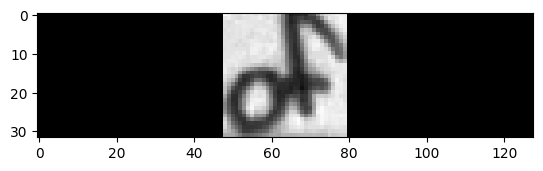

The word is identified as:  decnear
159 723 80 180


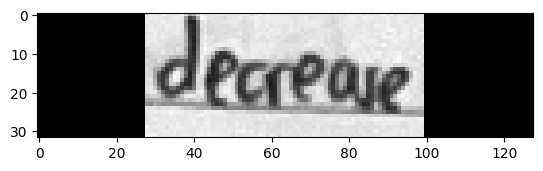

The word is identified as:  deaeae
149 713 94 196


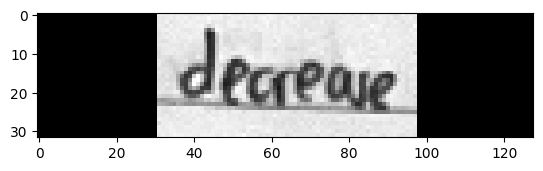

In [122]:
srno = 2

box = prediction_groups[0][srno]

res = WordBox(box)

DisplayWord(res)

box = prediction_groups[1][srno]

res = WordBox(box)

DisplayWord(res)

box = prediction_groups[2][srno]

res = WordBox(box)

DisplayWord(res)

The word is identified as:  trstng
194 1690 45 145


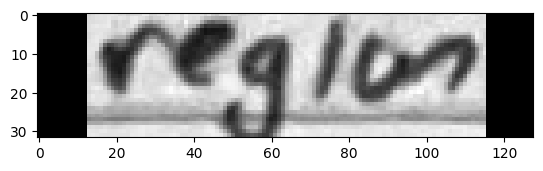

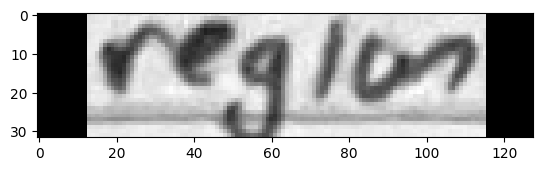

(128, 32, 1)
1/1 [==============================] - 0s 31ms/step
['a']
(128, 32, 1)
1/1 [==============================] - 0s 47ms/step
['a']


In [116]:
srno = 6

box = prediction_groups[0][srno]

res = WordBox(box)

DisplayWord(res) # The input shape is (128, 32, 1)

print(res.shape)

res = tf.reshape(res, [1] + list(res.shape))
preds = prediction_model.predict(res)
pred_texts = decode_batch_predictions(preds)
print(pred_texts)

print(contrast_increase(res)[0].shape)

res = contrast_increase(res)[0]

res = tf.reshape(res, [1] + list(res.shape))
preds = prediction_model.predict(res)
pred_texts = decode_batch_predictions(preds)
print(pred_texts)

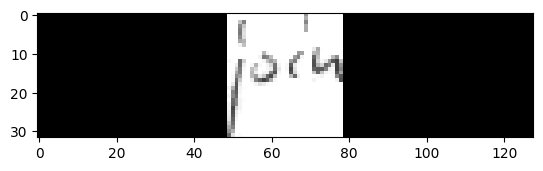

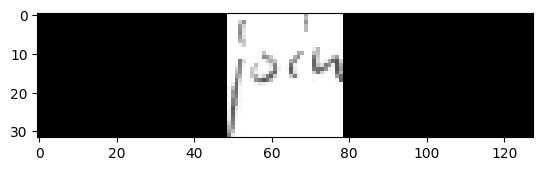

1/1 [==============================] - 0s 36ms/step
['join']


In [35]:
test_img = tf.io.read_file("C:\\Work\\Programming\\Hackathons\\Reprose\\Notes generation\\data\\words\\a04\\a04-035\\a04-035-03-02.png")
test_img = tf.image.decode_png(test_img, 1)
test_img = preprocess_image(test_img) # This returns a tensorflow image object

DisplayWord(test_img)

test_img = tf.reshape(test_img, [1] + list(test_img.shape))

preds = prediction_model.predict(test_img)
pred_texts = decode_batch_predictions(preds)
print(pred_texts)

# This needs to be fixed; gives a different otuput to the output given by the model in the other ipynb file

### Clustering approach

In [24]:
from sklearn.cluster import DBSCAN

In [25]:
part = 1
X = np.array(centers[part])

In [ ]:
# Hyperparameter optimisation with the silhouette score

from sklearn.metrics import calinski_harabasz_score, silhouette_score

scorecl = []
scoress = []

for i in range(100, 1000, 50):
    kmeans = MeanShift(bandwidth=i).fit(X)
    
    scorec = calinski_harabasz_score(X, kmeans.fit_predict(X))

    scorecl.append(scorec)

    scores = silhouette_score(X, kmeans.fit_predict(X))

    scoress.append(scores)

    print(i, scores, scorec)

segments = scores.index(max(scores))

print("The optimum number of segments in the text is :", segments)


In [ ]:
# Hyperparameter optimisation with bandwidth estimation

from sklearn.cluster import estimate_bandwidth

bd = estimate_bandwidth(X)

print(bd)

964.366537045092


In [ ]:
hyp = ( images[0].shape[0] ** 2 + images[0].shape[1] ** 2) ** 0.5 / 29

In [ ]:
hyp

148.62074165932364

In [ ]:
clustering = DBSCAN(eps=hyp, min_samples=2).fit(X)
clustering.labels_

array([ 0,  0,  1,  1,  1,  1,  1,  1,  1,  1,  2,  2,  2,  1,  1,  2, -1,
        1,  1,  1,  1,  1,  2,  1,  1,  2,  2,  2,  1,  2,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  2,  2,  2,  2,  2,  1,  1,  1,  1,  1,  2,  2,
        2,  2,  1,  1,  1,  3,  1,  3,  1,  3,  3, -1, -1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  4,  1,
        5,  4,  1,  1,  6,  6,  1,  1,  1,  6,  1,  5,  4,  1,  1,  6,  1,
        1,  4,  6,  4,  7,  7,  7,  7,  8,  8,  7,  7,  7,  7,  7,  7,  7,
        7,  7,  7,  9,  9,  7,  7,  7,  7,  7,  7,  7,  7,  7, -1, 10, 10,
        7, 11, 12, 13, 13, 11, 14, 12, 11, 12, 11, 14, 12, 14, -1, 12, 12,
       12, 14, 14, 15, 15, 15, 15, 15, 14, 14, 14, 14, -1, 14, 14, 14, 14,
       14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14,
       14, 14, 16, 16, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14,
       14, 14, 14, 14, 14

In [ ]:
output = clustering.labels_

NameError: name 'clustering' is not defined

In [ ]:
clustering.labels_

NameError: name 'clustering' is not defined

In [ ]:
text_group = []

covered = []

for i in range(len(output)):
    if output[i] not in covered:
        covered.append(output[i])
        text_group.append([ prediction_groups[part][i] ])
    else:
        ind = covered.index(output[i])
        text_group[ind].append( prediction_groups[part][i] )

back = [ images[0] for i in range(len(covered)) ]

NameError: name 'output' is not defined

In [ ]:
len(text_group)

0

In [ ]:
fig, axs = plt.subplots(nrows=len(back), figsize=(20, 40))
for ax, image, predictions in zip(axs, back, text_group):
    keras_ocr.tools.drawAnnotations(image=image, 
                                    predictions=predictions, 
                                    ax=ax)

<Axes: >

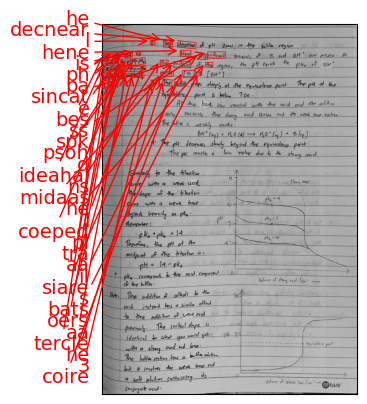

In [63]:
# When displaying one image

fig, ax = plt.subplots()
keras_ocr.tools.drawAnnotations(image=back[0], 
                                predictions=text_group[0], 
                                ax=ax)

#### Post-processing

In [94]:
# Explore the metrics available

a = clustering.components_

In [15]:
text_group[1]

NameError: name 'text_group' is not defined

In [ ]:
# Re-instert outliers into their groups

'''
The following are the steps to achieve this:
1. Identify which ones the outliers are (those groups with relatively less and far spread out words)
2. Find distances to big groups and see if the word integrates into the paragraphs (use average word distancing for this purpose)
3. Then add the word into the big group and remove from the small group
4. Do each word on a case by case basis
'''

# Idenfity the groups with outliers (size less than 5, label -1 or the above written criteria)
outliers = [covered.index(-1)]

for i in range(len(text_group)):
    # Check length less than 5
    